<a href="https://colab.research.google.com/github/hanshunyi0-cyber/mlp-s7-case-study/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s7-clinical-note-triage.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clinical Note Triage — from TF-IDF to transformer embeddings

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/racousin/data_science_practice/blob/main/website/public/modules/ms2a-machine-learning-practice/challenges/mlp-s7-clinical-note-triage.ipynb)

Read a free-text **medical transcription** and predict which of **12 clinical specialties**
(`spec_01` … `spec_12`) it belongs to: [challenge 174](https://ml-arena.com/viewchallenge/174)
on ML-Arena. Metric: **F1-macro**.

1. A **TF-IDF + logistic regression** baseline, submitted.
2. The same notes through a pretrained model from **Hugging Face**: text → tokens → embeddings
   → one vector per note.
3. Explore that vector space, then train an **MLP** on it.
4. Your turn: pick other models on Hugging Face, compare them, submit the best.

> In Colab: **Runtime → Change runtime type → T4 GPU**, then run the cells top to bottom.
> The only thing you must edit is your API token (your **Profile** page on ml-arena.com).

## 0. Setup

In [2]:
!pip install -q "mlarena-sdk>=3" transformers scikit-learn pandas matplotlib

import mlarena
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
from google.colab import userdata
API_TOKEN = userdata.get("MLARENA_API_KEY")  # <-- paste your token (Profile page)
CHALLENGE_ID = 174

client = mlarena.connect(api_key=API_TOKEN, base_url="https://ml-arena.com")

## 1. Get the data

`train.csv` holds `id, transcription, label`; `test.csv` holds `id, transcription`. Every model
below is scored on the **same** held-out 20 % of the training notes, so the numbers compare.

In [3]:
client.download_dataset(CHALLENGE_ID, "data/")
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

y = train["label"].values
classes = sorted(set(y))
idx_tr, idx_val = train_test_split(np.arange(len(train)), test_size=0.2,
                                   random_state=0, stratify=y)
print("train:", train.shape, "  test:", test.shape)
print(train["label"].value_counts().sort_index().to_dict())

train: (1951, 3)   test: (488, 2)
{'spec_01': 280, 'spec_02': 280, 'spec_03': 178, 'spec_04': 280, 'spec_05': 77, 'spec_06': 124, 'spec_07': 217, 'spec_08': 178, 'spec_09': 66, 'spec_10': 124, 'spec_11': 72, 'spec_12': 75}


Read a few notes before modelling. The specialty is hidden behind a code (`spec_01` …).

In [4]:
for _, row in train.sample(3, random_state=1).iterrows():
    print(f"--- {row['label']}  ({len(row['transcription'].split())} words)")
    print(row["transcription"][:600], "...\n")

--- spec_02  (878 words)
PREOPERATIVE DIAGNOSES:,1. Right shoulder rotator cuff tear.,2. Glenohumeral rotator cuff arthroscopy.,3. Degenerative joint disease.,POSTOPERATIVE DIAGNOSES:,1. Right shoulder rotator cuff tear.,2. Glenohumeral rotator cuff arthroscopy.,3. Degenerative joint disease.,PROCEDURE PERFORMED: ,Right shoulder hemiarthroplasty.,ANESTHESIA: , General.,ESTIMATED BLOOD LOSS: , Approximately 125 cc.,COMPLICATIONS:, None.,COMPONENTS: , A DePuy 10 mm global shoulder system stem was used cemented and a DePuy 44 x 21 mm articulating head was used.,BRIEF HISTORY: ,The patient is an 82-year-old right-hand dom ...

--- spec_08  (419 words)
CC: ,Depressed mental status.,HX: ,29y/o female fell down a flight of stairs on 2/20/95, striking the right side of her head. She then walked over to and lay down on a living room couch. She was found there, the next morning, by her boyfriend, poorly responsive and amidst a coffee ground like emesis. She was taken to a local ER and HCT reveal

**Questions**
- Which words would let a clinician guess the specialty? Where in the note are they?
- What does the text look like around the section headers? Is it clean prose?

## 2. Baseline: TF-IDF + logistic regression

Each note becomes a sparse vector: one column per word of the vocabulary, its count in the
note down-weighted by how common the word is across notes. No notion of meaning:
*myocardial* and *cardiac* are unrelated columns.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

text = train["transcription"]
baseline = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
baseline.fit(text.iloc[idx_tr], y[idx_tr])
print("validation F1-macro: %.3f" % f1_score(y[idx_val], baseline.predict(text.iloc[idx_val]), average="macro"))

validation F1-macro: 0.470


Refit on all the training notes, predict the test set, submit.

In [6]:
baseline.fit(text, y)
pd.DataFrame({"id": test["id"], "label": baseline.predict(test["transcription"])}).to_csv("submission.csv", index=False)
client.submit(challenge_id=CHALLENGE_ID, files=["submission.csv"], submission_name="tfidf-logreg")

{'submission_id': 9107,
 'deploy': {'deployment_id': 8817,
  'is_deployable': False,
  'is_settled': False,
  'is_uploadable': False,
  'last_status_message': 'Deployment queued successfully',
  'message': 'Deployment started successfully',
  'phase': 'deployment',
  'status': 'deploy_queue',
  'status_update_ts': '2026-09-29T12:10:17.996995Z'}}

## 3. Text → tokens

A transformer never reads words. Its **tokenizer** cuts the text into **subword tokens** from a
fixed vocabulary and maps each one to an integer **id**. We start with **GPT-2** (124 M
parameters, byte-level BPE, pretrained on general web text).

`MODEL_NAME` and `POOLING` are the two lines you will change in Section 7.

In [7]:
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "openai-community/gpt2"
POOLING = "mean"                      # "mean" or "cls", see Section 4

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
sentence = "Laparoscopic cholecystectomy under general anesthesia, 40 mg IV."
print(tokenizer.tokenize(sentence))
print(tokenizer(sentence)["input_ids"])

n_tokens = train["transcription"].map(lambda t: len(tokenizer(t)["input_ids"]))
print("vocabulary:", len(tokenizer), "  tokens per note:", n_tokens.describe()[["50%", "max"]].to_dict())

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1203 > 1024). Running this sequence through the model will result in indexing errors


['L', 'ap', 'ar', 'oscopic', 'Ġcho', 'le', 'cy', 'st', 'ectomy', 'Ġunder', 'Ġgeneral', 'Ġanesthesia', ',', 'Ġ40', 'Ġmg', 'ĠIV', '.']
[43, 499, 283, 48228, 1727, 293, 948, 301, 42505, 739, 2276, 49592, 11, 2319, 10527, 8363, 13]
vocabulary: 50257   tokens per note: {'50%': 598.0, 'max': 3553.0}


**Questions**
- How is each medical word split? What does the `Ġ` prefix encode?
- What fraction of the notes is longer than 512 tokens? Below we **truncate** at 512: which
  part of a note is lost, and does it matter for guessing the specialty?

## 4. Tokens → one vector per note

The model looks up a vector for each token id, then mixes them through its attention layers.
`last_hidden_state` has shape `(batch, n_tokens, hidden_size)`: one **contextual** vector per
token. The classifier needs **one** vector per note, so we **pool**:

- **`cls`**: BERT-style encoders put a `[CLS]` token first and pretrain it to summarise the
  sequence, so take `h[:, 0]`.
- **`mean`**: average the token vectors, skipping padding with the attention mask $m_t$:

$$e = \frac{\sum_t m_t\, h_t}{\sum_t m_t}$$

GPT-2 is a decoder: each token attends only to the tokens before it, so its first token has
seen nothing of the note, and mean pooling is the natural choice.

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
if tokenizer.pad_token is None:          # GPT-2 was pretrained without padding
    tokenizer.pad_token = tokenizer.eos_token

@torch.no_grad()
def embed(texts, batch_size=16, max_length=512):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(texts[i:i + batch_size], padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt").to(device)
        h = model(**enc).last_hidden_state                 # (batch, n_tokens, hidden)
        if POOLING == "cls":
            e = h[:, 0]
        else:
            m = enc["attention_mask"].unsqueeze(-1)         # 1 = token, 0 = padding
            e = (h * m).sum(1) / m.sum(1)
        out.append(e.float().cpu().numpy())
    return np.vstack(out)

X = embed(train["transcription"].tolist())
X_test = embed(test["transcription"].tolist())
print("embeddings:", X.shape, X_test.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

embeddings: (1951, 768) (488, 768)


### Look inside: attention on one sentence

Each layer lets every token build its vector from the others. Row *i* of an attention map is
how much token *i* (the query) takes from each token (the keys). GPT-2 has 12 layers of 12
heads; here are three of them, on GPT-2 whatever `MODEL_NAME` is.

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

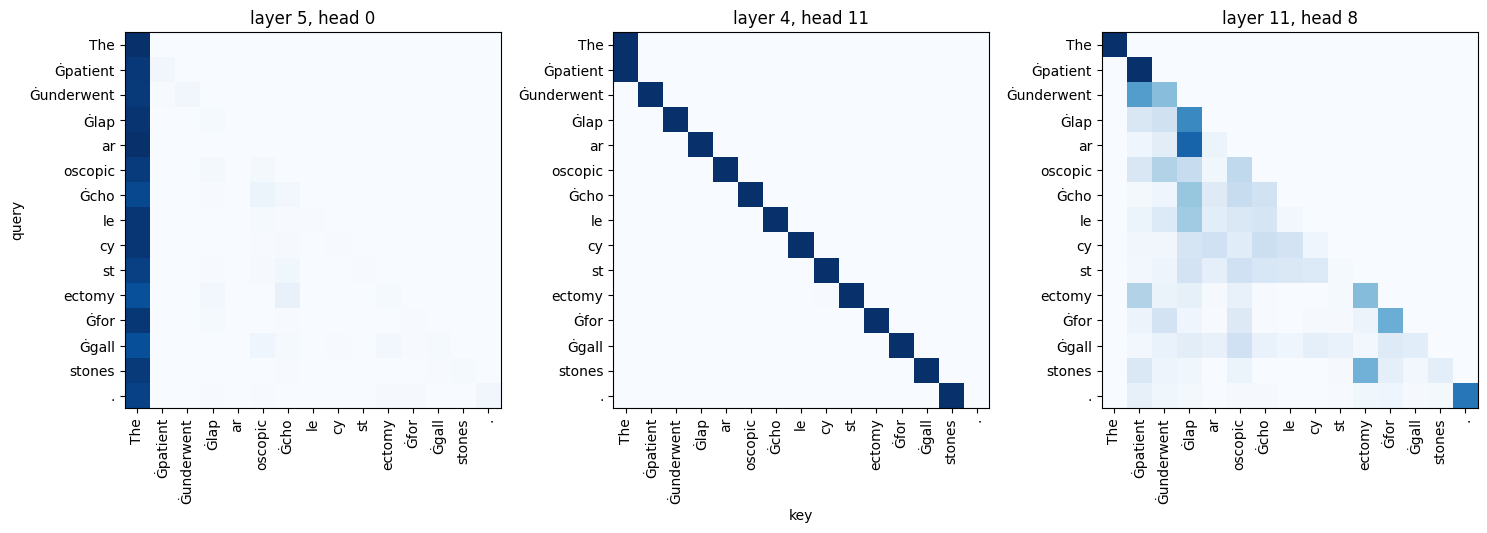

In [9]:
gpt2_tok = AutoTokenizer.from_pretrained("openai-community/gpt2")
viewer = AutoModel.from_pretrained("openai-community/gpt2", attn_implementation="eager")  # eager returns the weights
enc = gpt2_tok("The patient underwent laparoscopic cholecystectomy for gallstones.", return_tensors="pt")
with torch.no_grad():
    attentions = viewer(**enc, output_attentions=True).attentions   # per layer: (1, heads, n, n)
tokens = gpt2_tok.convert_ids_to_tokens(enc["input_ids"][0])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (layer, head) in zip(axes, [(5, 0), (4, 11), (11, 8)]):
    ax.imshow(attentions[layer][0, head], cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(tokens)), tokens, rotation=90); ax.set_yticks(range(len(tokens)), tokens)
    ax.set_title(f"layer {layer}, head {head}")
axes[0].set_ylabel("query"); axes[1].set_xlabel("key")
plt.tight_layout(); plt.show()

**Questions**
- Why is everything above the diagonal zero? Would it be with a BERT model?
- Each row sums to 1. Why does the first head send almost everything to `The`?
- What does the second head do? And in the third, which tokens does `stones` look at?

## 5. Explore the embedding space

Two notes are compared by the angle between their vectors, the **cosine similarity**
$\cos(a, b) = \frac{a \cdot b}{\lVert a \rVert\, \lVert b \rVert}$. Average the training
vectors of each specialty into a **centroid**, then classify a validation note by its most
similar centroid: no training at all.

nearest-centroid validation F1-macro: 0.202


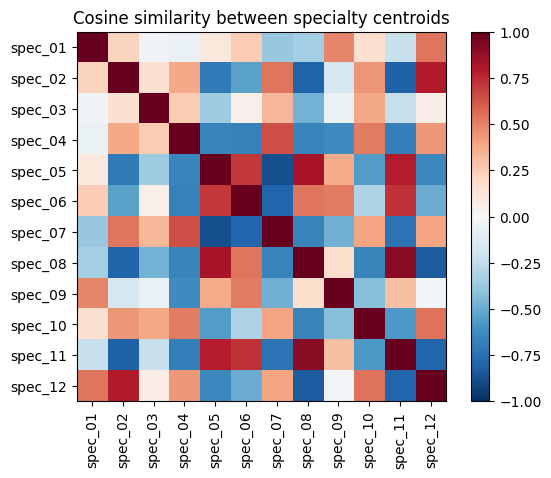

In [10]:
from sklearn.metrics.pairwise import cosine_similarity

Z = X - X[idx_tr].mean(0)                # centre the cloud (see the questions)
centroids = np.stack([Z[idx_tr][y[idx_tr] == c].mean(0) for c in classes])
nearest = np.array(classes)[cosine_similarity(Z[idx_val], centroids).argmax(1)]
print("nearest-centroid validation F1-macro: %.3f" % f1_score(y[idx_val], nearest, average="macro"))

plt.imshow(cosine_similarity(centroids), cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(12), classes, rotation=90); plt.yticks(range(12), classes)
plt.colorbar(); plt.title("Cosine similarity between specialty centroids"); plt.show()

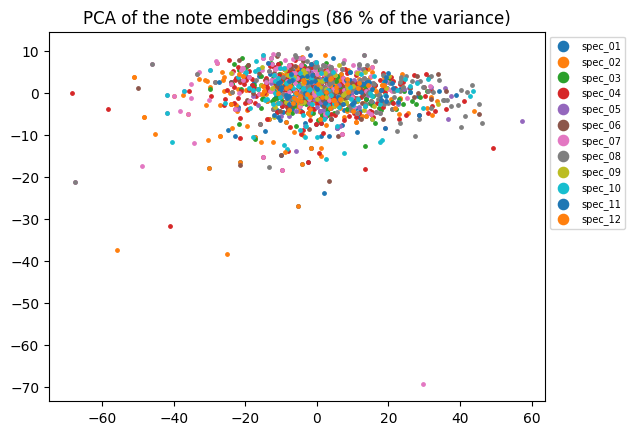

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2).fit(Z[idx_tr])
P = pca.transform(Z[idx_tr])
for c in classes:
    plt.scatter(*P[y[idx_tr] == c].T, s=6, label=c)
plt.legend(markerscale=3, fontsize=7, bbox_to_anchor=(1, 1))
plt.title("PCA of the note embeddings (%.0f %% of the variance)" % (100 * pca.explained_variance_ratio_.sum()))
plt.show()

**Questions**
- Print `cosine_similarity(X[:100]).mean()` on the raw, uncentred embeddings. What do you
  get, and why does it make raw cosine similarity useless here?
- Which specialties are closest to each other? Are they also the ones the baseline confuses?
- Do the specialties form clusters in the PCA plot? How much of the variance do these two
  axes keep?

## 6. An MLP on the embeddings

The pretrained model stays frozen; only a small classifier is trained on its vectors.

In [12]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler

labels = LabelEncoder().fit(y)           # the MLP's early stopping needs integer labels
mlp = make_pipeline(StandardScaler(),
                    MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-2, early_stopping=True,
                                  max_iter=500, random_state=0))
mlp.fit(X[idx_tr], labels.transform(y[idx_tr]))
pred = labels.inverse_transform(mlp.predict(X[idx_val]))
print("validation F1-macro: %.3f" % f1_score(y[idx_val], pred, average="macro"))

validation F1-macro: 0.555


Submit it once it beats your previous best on the validation split.

In [13]:
mlp.fit(X, labels.transform(y))
pd.DataFrame({"id": test["id"], "label": labels.inverse_transform(mlp.predict(X_test))}).to_csv("submission.csv", index=False)
client.submit(challenge_id=CHALLENGE_ID, files=["submission.csv"],
              submission_name=f"{MODEL_NAME.split('/')[-1]}-{POOLING}-mlp")

{'submission_id': 9108,
 'deploy': {'deployment_id': 8818,
  'is_deployable': False,
  'is_settled': False,
  'is_uploadable': False,
  'last_status_message': 'Deployment queued successfully',
  'message': 'Deployment started successfully',
  'phase': 'deployment',
  'status': 'deploy_queue',
  'status_update_ts': '2026-09-29T12:13:20.129132Z'}}

## 7. Your turn: choose the model

Change `MODEL_NAME` and `POOLING` in Section 3, rerun Sections 3 to 6, and keep a table:

| model | encoder / decoder | parameters | pretraining corpus | vocabulary | median tokens per note | pooling | validation F1 |
|---|---|---|---|---|---|---|---|

Some starting points (read each **model card** on huggingface.co before running it):

- general English: `google-bert/bert-base-uncased`, `distilbert/distilbert-base-uncased`,
  `FacebookAI/roberta-base`, `openai-community/gpt2-medium`, `Qwen/Qwen2.5-0.5B`
- trained for sentence similarity: `sentence-transformers/all-MiniLM-L6-v2`, `BAAI/bge-small-en-v1.5`
- scientific and biomedical text: `allenai/scibert_scivocab_uncased`,
  `dmis-lab/biobert-base-cased-v1.2`,
  `microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext`,
  `NeuML/pubmedbert-base-embeddings`
- clinical notes: `emilyalsentzer/Bio_ClinicalBERT`

Or search the hub yourself: [feature-extraction](https://huggingface.co/models?pipeline_tag=feature-extraction)
and [sentence-similarity](https://huggingface.co/models?pipeline_tag=sentence-similarity) models.

**Questions**
- Which pooling suits each model, and why? Try both on one encoder: does the answer match?
- Tokenize the Section 3 sentence with each tokenizer. Does a vocabulary that keeps medical
  words whole go with a better score?
- Which matters more here, the size of the model or the corpus it was pretrained on?
- Which specialties does your best model still get wrong (`classification_report`)? Does
  TF-IDF get them right?- The validation split has about 390 notes. How large must a gap in F1-macro be before you
  believe it?

In [14]:
import gc
import json
import os
from pathlib import Path
from IPython.display import display
from sklearn.metrics import classification_report

# Keep the exact eight columns requested in Section 7.
RESULT_COLUMNS = [
    "model", "encoder / decoder", "parameters", "pretraining corpus",
    "vocabulary", "median tokens per note", "pooling", "validation F1",
]
RESULT_PATH = Path("model_comparison.csv")
PREDICTION_PATH = Path("validation_predictions.json")
TOKEN_PATH = Path("token_diagnostics.json")
ERROR_PATH = Path("experiment_errors.csv")

# Corpus descriptions summarize the linked Hugging Face model cards. The parameter
# count and vocabulary size are read from each loaded model and tokenizer below.
MODEL_INFO = {
    "google-bert/bert-base-uncased": ("encoder", "general English", "BookCorpus + English Wikipedia"),
    "distilbert/distilbert-base-uncased": ("encoder", "general English", "distilled from BERT; BookCorpus + English Wikipedia"),
    "FacebookAI/roberta-base": ("encoder", "general English", "BookCorpus + Wikipedia + CC-News + OpenWebText + Stories"),
    "openai-community/gpt2-medium": ("decoder", "general English", "WebText"),
    "Qwen/Qwen2.5-0.5B": ("decoder", "general English", "multilingual pretraining; detailed corpus not disclosed"),
    "sentence-transformers/all-MiniLM-L6-v2": ("encoder", "sentence similarity", "MiniLM + more than 1B sentence pairs"),
    "BAAI/bge-small-en-v1.5": ("encoder", "sentence similarity", "general text + retrieval fine-tuning"),
    "allenai/scibert_scivocab_uncased": ("encoder", "scientific / biomedical", "scientific papers (Semantic Scholar)"),
    "dmis-lab/biobert-base-cased-v1.2": ("encoder", "scientific / biomedical", "BERT + PubMed abstracts + PMC full text"),
    "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext": ("encoder", "scientific / biomedical", "PubMed abstracts + PMC full text"),
    "NeuML/pubmedbert-base-embeddings": ("encoder", "scientific / biomedical", "BiomedBERT + PubMed title/abstract pairs"),
    "emilyalsentzer/Bio_ClinicalBERT": ("encoder", "clinical notes", "BioBERT + MIMIC-III clinical notes"),
}
MODEL_NAMES = list(MODEL_INFO)
assert len(MODEL_NAMES) == 12

def save_json(path, value):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2), encoding="utf-8")
    os.replace(temporary, path)

def load_json(path):
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else {}

results_df = pd.read_csv(RESULT_PATH) if RESULT_PATH.exists() else pd.DataFrame(columns=RESULT_COLUMNS)
results_df = results_df.reindex(columns=RESULT_COLUMNS)
results_df = results_df[results_df["model"].isin(MODEL_NAMES) &
                        results_df["pooling"].isin(["mean", "cls"])]
results_df = results_df.drop_duplicates(["model", "pooling"], keep="last").reset_index(drop=True)
predictions_store = load_json(PREDICTION_PATH)
token_diagnostics = load_json(TOKEN_PATH)
labels = LabelEncoder().fit(y)
assert len(idx_val) > 0 and set(labels.classes_) == set(classes)
print(f"Loaded {len(results_df)} saved experiment rows; target is 24.")


Loaded 0 saved experiment rows; target is 24.


In [15]:
def embed(texts, batch_size=16, max_length=512):
    """Section 4's frozen embeddings, with both poolings from one forward pass.

    The model and tokenizer are the current MODEL_NAME globals, as in Section 4.
    Only the batch size is reduced on CUDA out-of-memory errors.
    """
    outputs = {"mean": [], "cls": []}

    def one_batch(batch_texts):
        enc = tokenizer(batch_texts, padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt").to(device)
        with torch.inference_mode():
            h = model(**enc).last_hidden_state
            m = enc["attention_mask"].unsqueeze(-1)
            e_mean = (h * m).sum(1) / m.sum(1).clamp(min=1)
            e_cls = h[:, 0]
            return (e_mean.float().cpu().numpy(), e_cls.float().cpu().numpy())

    i = 0
    current_batch = batch_size
    while i < len(texts):
        try:
            mean_part, cls_part = one_batch(texts[i:i + current_batch])
        except RuntimeError as error:
            if "out of memory" not in str(error).lower() or current_batch == 1:
                raise
            current_batch = max(1, current_batch // 2)
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            print(f"{MODEL_NAME}: CUDA memory limit; retrying with batch_size={current_batch}")
            continue
        outputs["mean"].append(mean_part)
        outputs["cls"].append(cls_part)
        i += len(mean_part)
    return {pool: np.vstack(parts) for pool, parts in outputs.items()}

def new_mlp():
    # Exactly the Section 6 classifier and random state.
    return make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(256,), alpha=1e-2,
                                       early_stopping=True, max_iter=500, random_state=0))

def record_result(MODEL_NAME, POOLING, val_f1, parameter_count, token_lengths, pred):
    """Update one keyed result, display the eight-column table, then checkpoint."""
    global results_df
    architecture, category, corpus = MODEL_INFO[MODEL_NAME]
    row = {
        "model": MODEL_NAME,
        "encoder / decoder": architecture,
        "parameters": int(parameter_count),
        "pretraining corpus": corpus,
        "vocabulary": len(tokenizer),
        "median tokens per note": float(np.median(token_lengths)),
        "pooling": POOLING,
        "validation F1": float(val_f1),
    }
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
    results_df = results_df.drop_duplicates(["model", "pooling"], keep="last").reset_index(drop=True)
    assert list(results_df.columns) == RESULT_COLUMNS
    temporary = RESULT_PATH.with_suffix(".csv.tmp")
    results_df.to_csv(temporary, index=False)
    os.replace(temporary, RESULT_PATH)
    predictions_store[f"{MODEL_NAME}|{POOLING}"] = [str(label) for label in pred]
    save_json(PREDICTION_PATH, predictions_store)
    print(f"Recorded {len(results_df)}/24: {MODEL_NAME}, {POOLING}, F1={val_f1:.3f}")
    display(results_df)

def log_error(model_name, stage, error):
    row = pd.DataFrame([{"model": model_name, "stage": stage,
                         "error": f"{type(error).__name__}: {error}"}])
    row.to_csv(ERROR_PATH, mode="a", header=not ERROR_PATH.exists(), index=False)
    print(f"FAILED {model_name} ({stage}): {error}")

def run_model(model_name):
    global MODEL_NAME, POOLING, tokenizer, model, n_tokens, X, mlp, pred
    MODEL_NAME = model_name
    architecture, category, corpus = MODEL_INFO[MODEL_NAME]
    needed = [pool for pool in ("mean", "cls")
              if f"{MODEL_NAME}|{pool}" not in predictions_store or
              not ((results_df["model"] == MODEL_NAME) & (results_df["pooling"] == pool)).any()]
    if not needed:
        print(f"Already recorded both poolings for {MODEL_NAME}")
        return

    stage = "load"
    try:
        tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
        if tokenizer.pad_token is None:
            assert tokenizer.eos_token is not None, "Model needs a pad or eos token"
            tokenizer.pad_token = tokenizer.eos_token
        model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
        model.config.use_cache = False
        parameter_count = sum(p.numel() for p in model.parameters())

        stage = "tokenize"
        note_texts = train["transcription"].tolist()
        token_lengths = [len(ids) for ids in tokenizer(note_texts, padding=False,
                           truncation=False)["input_ids"]]
        n_tokens = pd.Series(token_lengths)
        # The three words retain their original spacing and case in Section 3.
        medical_words = ["Laparoscopic", " cholecystectomy", " anesthesia"]
        diagnostic = {
            "sentence_tokens": tokenizer.tokenize(sentence),
            "medical_word_tokens": {word.strip(): tokenizer.tokenize(word)
                                    for word in medical_words},
            "medical_word_piece_count": sum(len(tokenizer.tokenize(word))
                                             for word in medical_words),
            "fraction_over_512": float(np.mean(n_tokens > 512)),
            "median_tokens": float(np.median(n_tokens)),
            "category": category,
            "model_card": f"https://huggingface.co/{MODEL_NAME}",
        }
        token_diagnostics[MODEL_NAME] = diagnostic
        save_json(TOKEN_PATH, token_diagnostics)

        stage = "embed"
        pooled = embed(note_texts)
        for POOLING in needed:
            stage = f"fit {POOLING}"
            X = pooled[POOLING]
            mlp = new_mlp()
            mlp.fit(X[idx_tr], labels.transform(y[idx_tr]))
            pred = labels.inverse_transform(mlp.predict(X[idx_val]))
            val_f1 = f1_score(y[idx_val], pred, labels=classes,
                              average="macro", zero_division=0)
            record_result(MODEL_NAME, POOLING, val_f1, parameter_count,
                          token_lengths, pred)
    except Exception as error:
        log_error(MODEL_NAME, stage, error)
    finally:
        if "model" in globals():
            del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


In [16]:
# Run all 12 named candidates. Each model is loaded once and contributes two rows.
# Re-running this cell skips combinations already present in both checkpoints.
for model_name in MODEL_NAMES:
    run_model(model_name)

expected_pairs = {(name, pool) for name in MODEL_NAMES for pool in ("mean", "cls")}
completed_pairs = set(zip(results_df["model"], results_df["pooling"]))
missing_pairs = sorted(expected_pairs - completed_pairs)
print(f"Completed {len(completed_pairs & expected_pairs)}/24 configurations.")
if missing_pairs:
    print("Missing configurations:", missing_pairs)
    print(f"Inspect {ERROR_PATH} and rerun this cell after fixing the reported issue.")
else:
    print("All 24 configurations are complete.")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (142 outputs left out)

,model,encoder / decoder,parameters,pretraining corpus,vocabulary,median tokens per note,pooling,validation F1
0,google-bert/bert-base-uncased,encoder,109482240,BookCorpus + English Wikipedia,30522,608.0,mean,0.367746
1,google-bert/bert-base-uncased,encoder,109482240,BookCorpus + English Wikipedia,30522,608.0,cls,0.389716
2,distilbert/distilbert-base-uncased,encoder,66362880,distilled from BERT; BookCorpus + English Wiki...,30522,608.0,mean,0.496428
3,distilbert/distilbert-base-uncased,encoder,66362880,distilled from BERT; BookCorpus + English Wiki...,30522,608.0,cls,0.442558
4,FacebookAI/roberta-base,encoder,124645632,BookCorpus + Wikipedia + CC-News + OpenWebText...,50265,600.0,mean,0.462234
5,FacebookAI/roberta-base,encoder,124645632,BookCorpus + Wikipedia + CC-News + OpenWebText...,50265,600.0,cls,0.442563
6,openai-community/gpt2-medium,decoder,354823168,WebText,50257,598.0,mean,0.522578
7,openai-community/gpt2-medium,decoder,354823168,WebText,50257,598.0,cls,0.127712
8,Qwen/Qwen2.5-0.5B,decoder,494032768,multilingual pretraining; detailed corpus not ...,151665,598.0,mean,0.590446
9,Qwen/Qwen2.5-0.5B,decoder,494032768,multilingual pretraining; detailed corpus not ...,151665,598.0,cls,0.168790


Recorded 24/24: emilyalsentzer/Bio_ClinicalBERT, cls, F1=0.536


,model,encoder / decoder,parameters,pretraining corpus,vocabulary,median tokens per note,pooling,validation F1
0,google-bert/bert-base-uncased,encoder,109482240,BookCorpus + English Wikipedia,30522,608.0,mean,0.367746
1,google-bert/bert-base-uncased,encoder,109482240,BookCorpus + English Wikipedia,30522,608.0,cls,0.389716
2,distilbert/distilbert-base-uncased,encoder,66362880,distilled from BERT; BookCorpus + English Wiki...,30522,608.0,mean,0.496428
3,distilbert/distilbert-base-uncased,encoder,66362880,distilled from BERT; BookCorpus + English Wiki...,30522,608.0,cls,0.442558
4,FacebookAI/roberta-base,encoder,124645632,BookCorpus + Wikipedia + CC-News + OpenWebText...,50265,600.0,mean,0.462234
5,FacebookAI/roberta-base,encoder,124645632,BookCorpus + Wikipedia + CC-News + OpenWebText...,50265,600.0,cls,0.442563
6,openai-community/gpt2-medium,decoder,354823168,WebText,50257,598.0,mean,0.522578
7,openai-community/gpt2-medium,decoder,354823168,WebText,50257,598.0,cls,0.127712
8,Qwen/Qwen2.5-0.5B,decoder,494032768,multilingual pretraining; detailed corpus not ...,151665,598.0,mean,0.590446
9,Qwen/Qwen2.5-0.5B,decoder,494032768,multilingual pretraining; detailed corpus not ...,151665,598.0,cls,0.168790


Completed 24/24 configurations.
All 24 configurations are complete.


In [17]:
assert not missing_pairs, f"Complete all 24 configurations first: {missing_pairs}"
assert all(f"{name}|{pool}" in predictions_store for name, pool in expected_pairs)

scores = results_df.copy()
scores["validation F1"] = pd.to_numeric(scores["validation F1"])
scores["parameters"] = pd.to_numeric(scores["parameters"])
scores["eligible"] = ~((scores["encoder / decoder"] == "decoder") &
                       (scores["pooling"] == "cls"))
ranked = scores[scores["eligible"]].sort_values("validation F1", ascending=False)
print("All measured configurations (decoder first-token rows are diagnostic):")
display(scores.sort_values("validation F1", ascending=False))

# Question 1: compare poolings within every model.
pool_comparison = scores.pivot(index="model", columns="pooling", values="validation F1")
pool_comparison["mean - cls"] = pool_comparison["mean"] - pool_comparison["cls"]
pool_comparison["better measured pooling"] = np.where(
    pool_comparison["mean - cls"] >= 0, "mean", "cls")
print("1. Pooling comparison (decoder cls is not a genuine [CLS] summary):")
display(pool_comparison)
print("Mean wins for:", pool_comparison.index[pool_comparison["mean - cls"] >= 0].tolist())
print("First-token pooling wins for:",
      pool_comparison.index[pool_comparison["mean - cls"] < 0].tolist())
recommended_pool = {
    "sentence-transformers/all-MiniLM-L6-v2": "mean",
    "BAAI/bge-small-en-v1.5": "cls",
    "NeuML/pubmedbert-base-embeddings": "mean",
    "openai-community/gpt2-medium": "mean",
    "Qwen/Qwen2.5-0.5B": "mean",
}
for name, recommended in recommended_pool.items():
    measured = pool_comparison.loc[name, "better measured pooling"]
    print(f"{name}: card/architecture suggests {recommended}; measured {measured}; "
          f"match={recommended == measured}")

# Question 2: inspect actual medical-word splitting, not just total vocabulary.
token_table = pd.DataFrame([
    {"model": name, "medical word pieces": token_diagnostics[name]["medical_word_piece_count"],
     "Laparoscopic": token_diagnostics[name]["medical_word_tokens"]["Laparoscopic"],
     "cholecystectomy": token_diagnostics[name]["medical_word_tokens"]["cholecystectomy"],
     "anesthesia": token_diagnostics[name]["medical_word_tokens"]["anesthesia"],
     "fraction over 512": token_diagnostics[name]["fraction_over_512"]}
    for name in MODEL_NAMES
])
best_per_model = ranked.drop_duplicates("model")[["model", "validation F1"]]
token_table = token_table.merge(best_per_model, on="model", how="left")
print("2. Section 3 sentence tokenization and each model's best eligible F1:")
display(token_table)
piece_rank = token_table["medical word pieces"].rank()
score_rank = token_table["validation F1"].rank()
print("Spearman rank correlation (piece count vs F1):",
      round(piece_rank.corr(score_rank), 3))
print("Fewest pieces:", token_table.loc[token_table["medical word pieces"].idxmin(), "model"])
print("Highest eligible F1:", token_table.loc[token_table["validation F1"].idxmax(), "model"])
print("Read this as an association across 12 models, not a causal effect of vocabulary.")

# Question 3: compare parameter size with domain of pretraining.
size_table = best_per_model.merge(scores.drop_duplicates("model")[["model", "parameters"]], on="model")
size_table["category"] = size_table["model"].map(lambda name: MODEL_INFO[name][1])
size_table["parameters (M)"] = size_table["parameters"] / 1e6
print("3. Best eligible score per model, with size and corpus family:")
display(size_table.sort_values("validation F1", ascending=False))
print("Correlation of log parameter count with best F1:",
      round(np.log10(size_table["parameters"]).corr(size_table["validation F1"]), 3))
display(size_table.groupby("category", as_index=False)["validation F1"].agg(["count", "mean", "max"]))
print("Best corpus family by its top model:",
      size_table.loc[size_table["validation F1"].idxmax(), "category"])
print("These comparisons are observational: architecture, pooling, corpus, and size also differ.")

All measured configurations (decoder first-token rows are diagnostic):


,model,encoder / decoder,parameters,pretraining corpus,vocabulary,median tokens per note,pooling,validation F1,eligible
20,NeuML/pubmedbert-base-embeddings,encoder,109482240,BiomedBERT + PubMed title/abstract pairs,30522,543.0,mean,0.634430,True
21,NeuML/pubmedbert-base-embeddings,encoder,109482240,BiomedBERT + PubMed title/abstract pairs,30522,543.0,cls,0.612862,True
11,sentence-transformers/all-MiniLM-L6-v2,encoder,22713216,MiniLM + more than 1B sentence pairs,30522,608.0,cls,0.591624,True
8,Qwen/Qwen2.5-0.5B,decoder,494032768,multilingual pretraining; detailed corpus not ...,151665,598.0,mean,0.590446,True
18,microsoft/BiomedNLP-BiomedBERT-base-uncased-ab...,encoder,109482240,PubMed abstracts + PMC full text,30522,543.0,mean,0.563848,True
13,BAAI/bge-small-en-v1.5,encoder,33360000,general text + retrieval fine-tuning,30522,608.0,cls,0.560290,True
10,sentence-transformers/all-MiniLM-L6-v2,encoder,22713216,MiniLM + more than 1B sentence pairs,30522,608.0,mean,0.549375,True
14,allenai/scibert_scivocab_uncased,encoder,109918464,scientific papers (Semantic Scholar),31090,551.0,mean,0.537076,True
23,emilyalsentzer/Bio_ClinicalBERT,encoder,108310272,BioBERT + MIMIC-III clinical notes,28996,636.0,cls,0.536105,True
12,BAAI/bge-small-en-v1.5,encoder,33360000,general text + retrieval fine-tuning,30522,608.0,mean,0.530892,True


1. Pooling comparison (decoder cls is not a genuine [CLS] summary):


pooling,cls,mean,mean - cls,better measured pooling
model,,,,
BAAI/bge-small-en-v1.5,0.560290,0.530892,-0.029399,cls
FacebookAI/roberta-base,0.442563,0.462234,0.019672,mean
NeuML/pubmedbert-base-embeddings,0.612862,0.634430,0.021568,mean
Qwen/Qwen2.5-0.5B,0.168790,0.590446,0.421657,mean
allenai/scibert_scivocab_uncased,0.492360,0.537076,0.044716,mean
distilbert/distilbert-base-uncased,0.442558,0.496428,0.053870,mean
dmis-lab/biobert-base-cased-v1.2,0.354251,0.501826,0.147575,mean
emilyalsentzer/Bio_ClinicalBERT,0.536105,0.502680,-0.033425,cls
google-bert/bert-base-uncased,0.389716,0.367746,-0.021970,cls


Mean wins for: ['FacebookAI/roberta-base', 'NeuML/pubmedbert-base-embeddings', 'Qwen/Qwen2.5-0.5B', 'allenai/scibert_scivocab_uncased', 'distilbert/distilbert-base-uncased', 'dmis-lab/biobert-base-cased-v1.2', 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext', 'openai-community/gpt2-medium']
First-token pooling wins for: ['BAAI/bge-small-en-v1.5', 'emilyalsentzer/Bio_ClinicalBERT', 'google-bert/bert-base-uncased', 'sentence-transformers/all-MiniLM-L6-v2']
sentence-transformers/all-MiniLM-L6-v2: card/architecture suggests mean; measured cls; match=False
BAAI/bge-small-en-v1.5: card/architecture suggests cls; measured cls; match=True
NeuML/pubmedbert-base-embeddings: card/architecture suggests mean; measured mean; match=True
openai-community/gpt2-medium: card/architecture suggests mean; measured mean; match=True
Qwen/Qwen2.5-0.5B: card/architecture suggests mean; measured mean; match=True
2. Section 3 sentence tokenization and each model's best eligible F1:


,model,medical word pieces,Laparoscopic,cholecystectomy,anesthesia,fraction over 512,validation F1
0,google-bert/bert-base-uncased,11,"[lap, ##aro, ##scopic]","[cho, ##le, ##cy, ##ste, ##ct, ##omy]","[an, ##esthesia]",0.579190,0.389716
1,distilbert/distilbert-base-uncased,11,"[lap, ##aro, ##scopic]","[cho, ##le, ##cy, ##ste, ##ct, ##omy]","[an, ##esthesia]",0.579190,0.496428
2,FacebookAI/roberta-base,10,"[L, ap, ar, oscopic]","[Ġcho, le, cy, st, ectomy]",[Ġanesthesia],0.580728,0.462234
3,openai-community/gpt2-medium,10,"[L, ap, ar, oscopic]","[Ġcho, le, cy, st, ectomy]",[Ġanesthesia],0.578165,0.522578
4,Qwen/Qwen2.5-0.5B,9,"[L, ap, ar, oscopic]","[Ġch, olec, yst, ectomy]",[Ġanesthesia],0.578165,0.590446
5,sentence-transformers/all-MiniLM-L6-v2,11,"[lap, ##aro, ##scopic]","[cho, ##le, ##cy, ##ste, ##ct, ##omy]","[an, ##esthesia]",0.579190,0.591624
6,BAAI/bge-small-en-v1.5,11,"[lap, ##aro, ##scopic]","[cho, ##le, ##cy, ##ste, ##ct, ##omy]","[an, ##esthesia]",0.579190,0.560290
7,allenai/scibert_scivocab_uncased,4,[laparoscopic],"[cholecyst, ##ectomy]",[anesthesia],0.541261,0.537076
8,dmis-lab/biobert-base-cased-v1.2,12,"[lap, ##aro, ##scopic]","[ch, ##ole, ##cy, ##ste, ##ct, ##omy]","[an, ##est, ##hesia]",0.606356,0.501826
9,microsoft/BiomedNLP-BiomedBERT-base-uncased-ab...,3,[laparoscopic],[cholecystectomy],[anesthesia],0.529985,0.563848


Spearman rank correlation (piece count vs F1): -0.469
Fewest pieces: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
Highest eligible F1: NeuML/pubmedbert-base-embeddings
Read this as an association across 12 models, not a causal effect of vocabulary.
3. Best eligible score per model, with size and corpus family:


,model,validation F1,parameters,category,parameters (M)
0,NeuML/pubmedbert-base-embeddings,0.634430,109482240,scientific / biomedical,109.482240
1,sentence-transformers/all-MiniLM-L6-v2,0.591624,22713216,sentence similarity,22.713216
2,Qwen/Qwen2.5-0.5B,0.590446,494032768,general English,494.032768
3,microsoft/BiomedNLP-BiomedBERT-base-uncased-ab...,0.563848,109482240,scientific / biomedical,109.482240
4,BAAI/bge-small-en-v1.5,0.560290,33360000,sentence similarity,33.360000
5,allenai/scibert_scivocab_uncased,0.537076,109918464,scientific / biomedical,109.918464
6,emilyalsentzer/Bio_ClinicalBERT,0.536105,108310272,clinical notes,108.310272
7,openai-community/gpt2-medium,0.522578,354823168,general English,354.823168
8,dmis-lab/biobert-base-cased-v1.2,0.501826,108310272,scientific / biomedical,108.310272
9,distilbert/distilbert-base-uncased,0.496428,66362880,general English,66.362880


Correlation of log parameter count with best F1: -0.068


,category,count,mean,max
0,clinical notes,1,0.536105,0.536105
1,general English,5,0.492280,0.590446
2,scientific / biomedical,4,0.559295,0.634430
3,sentence similarity,2,0.575957,0.591624


Best corpus family by its top model: scientific / biomedical
These comparisons are observational: architecture, pooling, corpus, and size also differ.


In [18]:
# Questions 4 and 5: compare the winner with TF-IDF and quantify a score gap.
best_row = ranked.iloc[0]
runner_row = ranked.iloc[1]
best_key = f"{best_row['model']}|{best_row['pooling']}"
runner_key = f"{runner_row['model']}|{runner_row['pooling']}"
best_pred = np.array(predictions_store[best_key])
runner_pred = np.array(predictions_store[runner_key])
assert len(best_pred) == len(runner_pred) == len(idx_val)

baseline_val = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))
baseline_val.fit(text.iloc[idx_tr], y[idx_tr])
tfidf_pred = baseline_val.predict(text.iloc[idx_val])
best_report = classification_report(y[idx_val], best_pred, labels=classes,
                                    zero_division=0, output_dict=True)
tfidf_report = classification_report(y[idx_val], tfidf_pred, labels=classes,
                                     zero_division=0, output_dict=True)
class_table = pd.DataFrame([
    {"specialty": c, "support": best_report[c]["support"],
     "best F1": best_report[c]["f1-score"],
     "TF-IDF F1": tfidf_report[c]["f1-score"],
     "best errors": int(np.sum((y[idx_val] == c) & (best_pred != c))),
     "TF-IDF correct among best errors": int(np.sum(
         (y[idx_val] == c) & (best_pred != c) & (tfidf_pred == c)))}
    for c in classes
])
print(f"4. Best eligible model: {best_key}; F1={best_row['validation F1']:.3f}")
print(classification_report(y[idx_val], best_pred, labels=classes, zero_division=0))
display(class_table.sort_values(["best F1", "support"]))
weakest = class_table.nsmallest(3, "best F1")
print("Lowest three specialty F1 scores:", weakest["specialty"].tolist())
print("TF-IDF correct among the best model's errors in those classes:",
      dict(zip(weakest["specialty"], weakest["TF-IDF correct among best errors"])))

# Paired, stratified bootstrap keeps each specialty's validation-set size fixed.
rng = np.random.default_rng(0)
positions = [np.flatnonzero(y[idx_val] == c) for c in classes]
boot_differences = np.empty(2000)
for b in range(len(boot_differences)):
    sample = np.concatenate([rng.choice(pos, size=len(pos), replace=True)
                             for pos in positions])
    top_f1 = f1_score(y[idx_val][sample], best_pred[sample], labels=classes,
                      average="macro", zero_division=0)
    next_f1 = f1_score(y[idx_val][sample], runner_pred[sample], labels=classes,
                       average="macro", zero_division=0)
    boot_differences[b] = top_f1 - next_f1
interval = np.quantile(boot_differences, [0.025, 0.975])
observed_gap = best_row["validation F1"] - runner_row["validation F1"]
print(f"5. {best_key} vs {runner_key}: observed F1 gap={observed_gap:.3f}; "
      f"paired 95% bootstrap interval=[{interval[0]:.3f}, {interval[1]:.3f}].")
if interval[0] <= 0 <= interval[1]:
    print("The interval includes zero; this split does not establish a clear lead.")
else:
    print("The interval excludes zero on this split; confirm on fresh data before a strong claim.")
print("Selection among 24 experiments makes this interval optimistic as a final generalization claim.")


4. Best eligible model: NeuML/pubmedbert-base-embeddings|mean; F1=0.634
              precision    recall  f1-score   support

     spec_01       0.38      0.27      0.32        56
     spec_02       0.61      0.79      0.69        56
     spec_03       0.76      0.86      0.81        36
     spec_04       0.74      0.66      0.70        56
     spec_05       0.61      0.93      0.74        15
     spec_06       0.84      0.84      0.84        25
     spec_07       0.45      0.23      0.30        44
     spec_08       0.54      0.72      0.62        36
     spec_09       0.85      0.85      0.85        13
     spec_10       0.68      0.84      0.75        25
     spec_11       0.69      0.64      0.67        14
     spec_12       0.36      0.33      0.34        15

    accuracy                           0.62       391
   macro avg       0.63      0.66      0.63       391
weighted avg       0.61      0.62      0.60       391



,specialty,support,best F1,TF-IDF F1,best errors,TF-IDF correct among best errors
6,spec_07,44.0,0.303030,0.311111,34,12
0,spec_01,56.0,0.315789,0.281481,41,9
11,spec_12,15.0,0.344828,0.000000,10,0
7,spec_08,36.0,0.619048,0.485714,10,1
10,spec_11,14.0,0.666667,0.250000,5,0
1,spec_02,56.0,0.687500,0.691729,12,5
3,spec_04,56.0,0.698113,0.666667,19,11
4,spec_05,15.0,0.736842,0.416667,1,0
9,spec_10,25.0,0.750000,0.627451,4,1
2,spec_03,36.0,0.805195,0.687500,5,3


Lowest three specialty F1 scores: ['spec_07', 'spec_01', 'spec_12']
TF-IDF correct among the best model's errors in those classes: {'spec_07': 12, 'spec_01': 9, 'spec_12': 0}
5. NeuML/pubmedbert-base-embeddings|mean vs NeuML/pubmedbert-base-embeddings|cls: observed F1 gap=0.022; paired 95% bootstrap interval=[-0.012, 0.056].
The interval includes zero; this split does not establish a clear lead.
Selection among 24 experiments makes this interval optimistic as a final generalization claim.


In [19]:
assert not missing_pairs and len(ranked) == 22  # 24 rows, excluding two decoder-cls controls
if float(best_row["validation F1"]) <= 0.555:
    print("No new candidate beat the Section 6 GPT-2 mean baseline (0.555); no new submission.")
else:
    MODEL_NAME = str(best_row["model"])
    POOLING = str(best_row["pooling"])
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    model = AutoModel.from_pretrained(MODEL_NAME).to(device).eval()
    model.config.use_cache = False
    X = embed(train["transcription"].tolist())[POOLING]
    X_test = embed(test["transcription"].tolist())[POOLING]
    mlp = new_mlp()
    mlp.fit(X, labels.transform(y))
    final_pred = labels.inverse_transform(mlp.predict(X_test))
    submission = pd.DataFrame({"id": test["id"], "label": final_pred})
    assert list(submission.columns) == ["id", "label"]
    assert len(submission) == len(test) and submission["id"].equals(test["id"])
    assert submission["label"].isin(classes).all() and not submission.isna().any().any()
    submission.to_csv("submission.csv", index=False)
    display(submission.head())
    response = client.submit(challenge_id=CHALLENGE_ID, files=["submission.csv"],
                             submission_name=f"{MODEL_NAME.split('/')[-1]}-{POOLING}-mlp")
    print("Submitted:", response)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

,id,label
0,doc_001539,spec_12
1,doc_000659,spec_08
2,doc_001984,spec_12
3,doc_001853,spec_05
4,doc_001730,spec_10


Submitted: {'submission_id': 9110, 'deploy': {'deployment_id': 8820, 'is_deployable': False, 'is_settled': False, 'is_uploadable': False, 'last_status_message': 'Deployment queued successfully', 'message': 'Deployment started successfully', 'phase': 'deployment', 'status': 'deploy_queue', 'status_update_ts': '2026-09-29T12:37:05.170172Z'}}
